<a href="https://colab.research.google.com/github/megaxy07/apriori-fault-analysis/blob/main/Apriori_ECE_Fault_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [33]:
import pandas as pd

# Define 10 ECE Diagnostic Log Transactions
fault_transactions = [
    ['Overcurrent_Trip', 'High_MOSFET_Temp', 'Voltage_Sag'],
    ['Overcurrent_Trip', 'High_MOSFET_Temp', 'Gate_Driver_Fault'],
    ['Overcurrent_Trip', 'High_MOSFET_Temp', 'Voltage_Sag', 'Gate_Driver_Fault'],
    ['Overcurrent_Trip', 'High_MOSFET_Temp'],
    ['Voltage_Sag', 'PWM_Signal_Loss', 'MCU_Reset'],
    ['Overcurrent_Trip', 'High_MOSFET_Temp', 'Voltage_Sag'],
    ['High_MOSFET_Temp', 'Gate_Driver_Fault'],
    ['Overcurrent_Trip', 'Voltage_Sag', 'MCU_Reset'],
    ['Overcurrent_Trip', 'High_MOSFET_Temp', 'Voltage_Sag', 'Gate_Driver_Fault'],
    ['Voltage_Sag', 'PWM_Signal_Loss']
]

# Quote the fault list so Pandas parses it as a single 'Fault_Flags' column
formatted_rows = [f'"{",".join(tx)}"' for tx in fault_transactions]

with open('ece_fault_transactions.csv', 'w') as f:
    f.write("Transaction_ID,Fault_Flags\n")
    for idx, row in enumerate(formatted_rows, 1):
        f.write(f"T{idx},{row}\n")

print("✅ 'ece_fault_transactions.csv' created and saved successfully!")

# Display the raw saved CSV
df_raw = pd.read_csv('ece_fault_transactions.csv')
print("\n--- Raw Saved CSV Preview ---")
print(df_raw.to_string(index=False))

✅ 'ece_fault_transactions.csv' created and saved successfully!

--- Raw Saved CSV Preview ---
Transaction_ID                                                     Fault_Flags
            T1                   Overcurrent_Trip,High_MOSFET_Temp,Voltage_Sag
            T2             Overcurrent_Trip,High_MOSFET_Temp,Gate_Driver_Fault
            T3 Overcurrent_Trip,High_MOSFET_Temp,Voltage_Sag,Gate_Driver_Fault
            T4                               Overcurrent_Trip,High_MOSFET_Temp
            T5                           Voltage_Sag,PWM_Signal_Loss,MCU_Reset
            T6                   Overcurrent_Trip,High_MOSFET_Temp,Voltage_Sag
            T7                              High_MOSFET_Temp,Gate_Driver_Fault
            T8                          Overcurrent_Trip,Voltage_Sag,MCU_Reset
            T9 Overcurrent_Trip,High_MOSFET_Temp,Voltage_Sag,Gate_Driver_Fault
           T10                                     Voltage_Sag,PWM_Signal_Loss


In [34]:
!pip install mlxtend -q

import warnings
warnings.filterwarnings('ignore')

import pandas as pd
from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import apriori, association_rules

# 1. Define Thresholds
MIN_SUPPORT = 0.40      # 40%
MIN_CONFIDENCE = 0.60   # 60%

# 2. Load CSV and reconstruct list of transactions
df_csv = pd.read_csv('ece_fault_transactions.csv')
loaded_transactions = [flags.split(',') for flags in df_csv['Fault_Flags']]

# 3. One-Hot Encoding
te = TransactionEncoder()
te_ary = te.fit(loaded_transactions).transform(loaded_transactions)
df_encoded = pd.DataFrame(te_ary, columns=te.columns_)

# 4. Apriori Frequent Itemset Generation
frequent_itemsets = apriori(df_encoded, min_support=MIN_SUPPORT, use_colnames=True)

# 5. Association Rules Generation
rules = association_rules(frequent_itemsets, metric="confidence", min_threshold=MIN_CONFIDENCE)

# Format rules for plotting and readability
rules_df = rules[['antecedents', 'consequents', 'support', 'confidence', 'lift']].copy()
rules_df['antecedents'] = rules_df['antecedents'].apply(lambda x: ", ".join(list(x)))
rules_df['consequents'] = rules_df['consequents'].apply(lambda x: ", ".join(list(x)))
rules_df['Rule'] = rules_df['antecedents'] + " → " + rules_df['consequents']

print(f"=== Frequent Itemsets (Min Support >= {MIN_SUPPORT*100:.0f}%) ===")
print(frequent_itemsets)

print(f"\n=== Extracted Association Rules (Min Confidence >= {MIN_CONFIDENCE*100:.0f}%) ===")
print(rules_df[['Rule', 'support', 'confidence', 'lift']].to_string(index=False))

=== Frequent Itemsets (Min Support >= 40%) ===
   support                                           itemsets
0      0.4                                (Gate_Driver_Fault)
1      0.7                                 (High_MOSFET_Temp)
2      0.7                                 (Overcurrent_Trip)
3      0.7                                      (Voltage_Sag)
4      0.4              (High_MOSFET_Temp, Gate_Driver_Fault)
5      0.6               (Overcurrent_Trip, High_MOSFET_Temp)
6      0.4                    (Voltage_Sag, High_MOSFET_Temp)
7      0.5                    (Voltage_Sag, Overcurrent_Trip)
8      0.4  (Voltage_Sag, Overcurrent_Trip, High_MOSFET_Temp)

=== Extracted Association Rules (Min Confidence >= 60%) ===
                                            Rule  support  confidence     lift
            Gate_Driver_Fault → High_MOSFET_Temp      0.4    1.000000 1.428571
             Overcurrent_Trip → High_MOSFET_Temp      0.6    0.857143 1.224490
             High_MOSFET_Temp → Ove

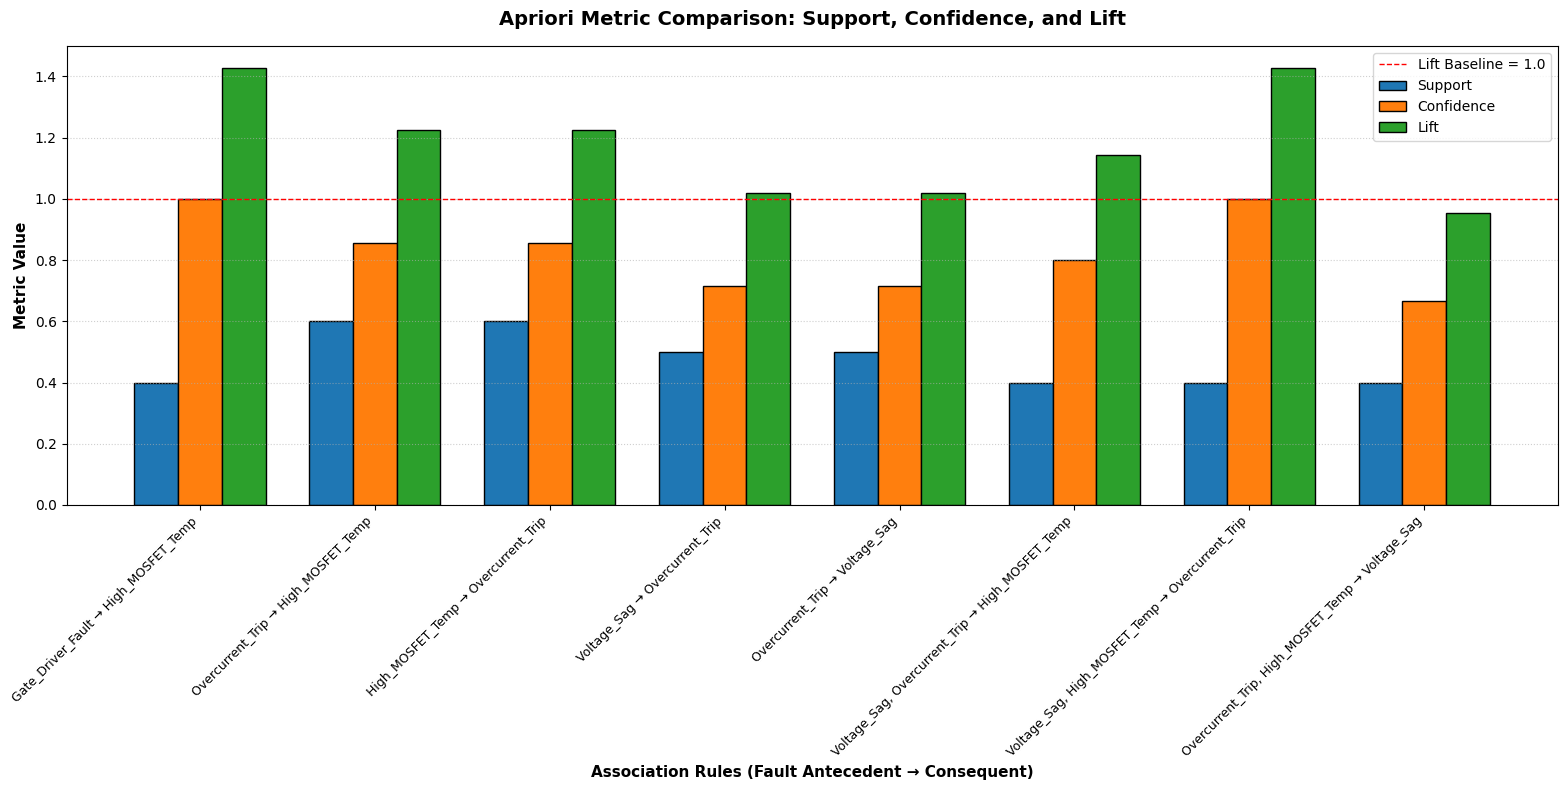

In [35]:
import matplotlib.pyplot as plt
import numpy as np

# Extract metrics for plotting
rule_labels = rules_df['Rule'].values
supports = rules_df['support'].values
confidences = rules_df['confidence'].values
lifts = rules_df['lift'].values

x = np.arange(len(rule_labels))
width = 0.25  # Bar width

plt.figure(figsize=(16, 8))

# Grouped bar chart for Support, Confidence, and Lift
plt.bar(x - width, supports, width, label='Support', color='#1f77b4', edgecolor='black')
plt.bar(x, confidences, width, label='Confidence', color='#ff7f0e', edgecolor='black')
plt.bar(x + width, lifts, width, label='Lift', color='#2ca02c', edgecolor='black')

# Plot customization
plt.title('Apriori Metric Comparison: Support, Confidence, and Lift', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Association Rules (Fault Antecedent → Consequent)', fontsize=11, fontweight='bold')
plt.ylabel('Metric Value', fontsize=11, fontweight='bold')
plt.xticks(x, rule_labels, rotation=45, ha='right', fontsize=9)
plt.axhline(y=1.0, color='red', linestyle='--', linewidth=1, label='Lift Baseline = 1.0')
plt.legend(fontsize=10, loc='upper right')
plt.grid(axis='y', linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()